# 01 FMA exploratory analysis: class balance, data quality, feature scale, redundancy, relevance and PCA (training split)

In [1]:
import sys; sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from src.config import FIGURES, SEED
from src.data import load_fma, fma_xy, fma_feature_cols

fma = load_fma()
feat_cols = fma_feature_cols(fma)
X, y = fma_xy(fma, "training")  # every statistic below uses the training split only
genres = sorted(y.unique())
group = pd.Series(["_".join(c.split("_")[:-2]) for c in feat_cols], index=feat_cols)  # mfcc_mean_01 -> mfcc
X.shape

(6400, 518)

## 1. Class balance

split,training,validation,test
genre,,,
Electronic,800,100,100
Experimental,800,100,100
Folk,800,100,100
Hip-Hop,800,100,100
Instrumental,800,100,100
International,800,100,100
Pop,800,100,100
Rock,800,100,100


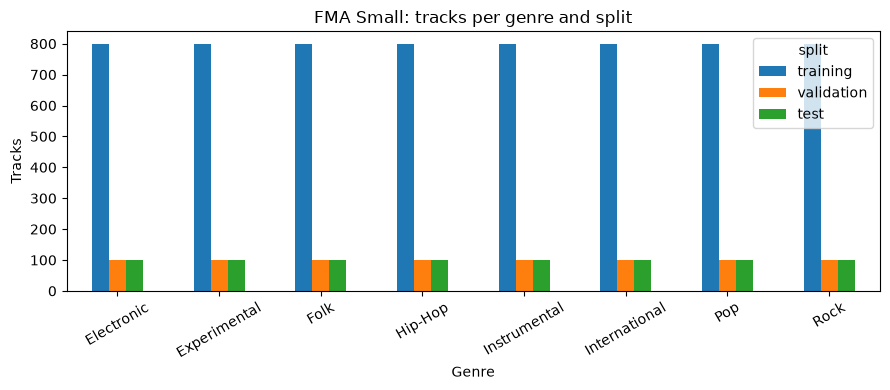

In [2]:
counts = pd.crosstab(fma["genre"], fma["split"])[["training", "validation", "test"]]
fig, ax = plt.subplots(figsize=(9, 4))
counts.plot.bar(ax=ax, rot=30)
ax.set(xlabel="Genre", ylabel="Tracks", title="FMA Small: tracks per genre and split")
fig.tight_layout()
fig.savefig(FIGURES / "fma_class_counts.png", dpi=200)
counts

## 2. Data quality

In [3]:
print("missing:", int(X.isna().sum().sum()),
      "| infinite:", int(np.isinf(X.to_numpy()).sum()),
      "| constant columns:", int((X.nunique() <= 1).sum()))

# Identical feature rows across all 8,000 tracks; a group holding two genres is label noise.
row_hash = pd.util.hash_pandas_object(fma[feat_cols], index=False)
dup = fma.loc[row_hash.duplicated(keep=False), ["genre", "split"]].assign(group=row_hash)
print(len(dup), "tracks in", dup["group"].nunique(), "duplicate groups;",
      "groups crossing splits:", int((dup.groupby("group")["split"].nunique() > 1).sum()))
dup[dup.groupby("group")["genre"].transform("nunique") > 1]

missing: 0 | infinite: 0 | constant columns: 0
30 tracks in 13 duplicate groups; groups crossing splits: 0


,genre,split,group
track_id,,,
57371,Instrumental,training,11710904226456362145
72149,Experimental,training,11710904226456362145


In [4]:
# z-score with training mean and std; |z| > 5 marks an extreme value.
z = (X - X.mean()) / X.std()
outliers = (z.abs() > 5).mean().groupby(group).mean().mul(100).round(2)
outliers.rename("% of values with |z| > 5").to_frame()

,% of values with |z| > 5
chroma_cens,0.23
chroma_cqt,0.17
chroma_stft,0.19
mfcc,0.14
rmse,0.21
spectral_bandwidth,0.12
spectral_centroid,0.27
spectral_contrast,0.15
spectral_rolloff,0.27
tonnetz,0.20


Decision: keep outliers and duplicates. The features are measurements of real audio, not entry errors, so extreme values carry genre information (e.g. very loud or very quiet tracks). Duplicates never cross splits, so they cannot leak test tracks into training. Trees are insensitive to outliers, and standardisation stops them dominating distance-based models.

## 3. Feature groups

In [5]:
group.value_counts().rename("columns").to_frame()

,columns
mfcc,140
chroma_cens,84
chroma_cqt,84
chroma_stft,84
spectral_contrast,49
tonnetz,42
rmse,7
spectral_bandwidth,7
spectral_centroid,7
spectral_rolloff,7


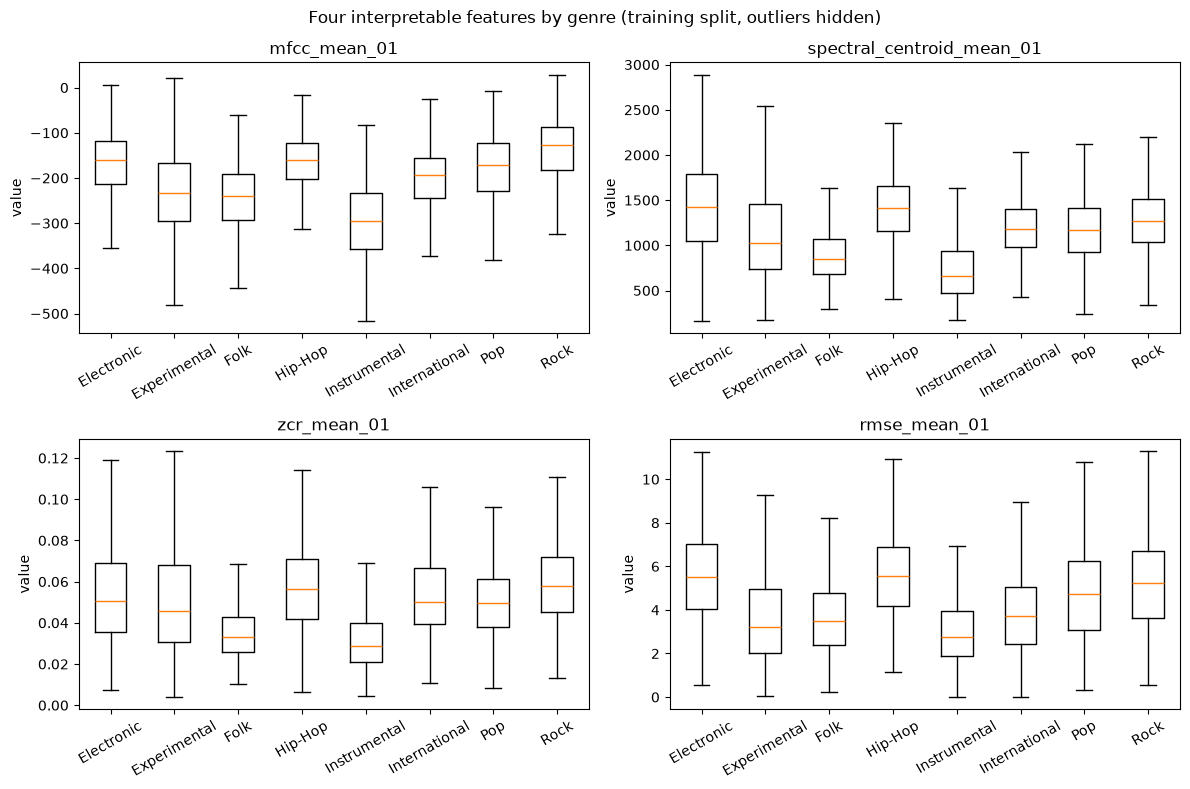

In [6]:
show = ["mfcc_mean_01", "spectral_centroid_mean_01", "zcr_mean_01", "rmse_mean_01"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, show):
    ax.boxplot([X.loc[y == g, col] for g in genres], tick_labels=genres, showfliers=False)
    ax.set(title=col, ylabel="value")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Four interpretable features by genre (training split, outliers hidden)")
fig.tight_layout()
fig.savefig(FIGURES / "fma_feature_boxplots.png", dpi=200)

## 4. Scale and skew

In [7]:
# Spread of standard deviations and share of strongly skewed features (|skew| > 1) per descriptor group.
stats = pd.DataFrame({"std": X.std(), "abs_skew": X.apply(skew).abs()}).groupby(group).agg(
    columns=("std", "size"), median_std=("std", "median"), min_std=("std", "min"), max_std=("std", "max"),
    pct_skewed=("abs_skew", lambda s: 100 * (s > 1).mean()))
print(f"feature std ranges from {X.std().min():.3g} to {X.std().max():.3g}")
stats.round(3)

feature std ranges from 0.00153 to 1.24e+03


,columns,median_std,min_std,max_std,pct_skewed
chroma_cens,84,0.084,0.020,6.749,36.905
chroma_cqt,84,0.123,0.003,16.879,45.238
chroma_stft,84,0.121,0.002,10.208,47.619
mfcc,140,5.328,0.289,100.132,27.857
rmse,7,2.477,0.413,10.055,71.429
spectral_bandwidth,7,315.574,1.630,479.884,42.857
spectral_centroid,7,271.954,2.383,1116.895,85.714
spectral_contrast,49,2.581,0.273,7.905,40.816
spectral_rolloff,7,507.409,2.363,1235.263,57.143
tonnetz,42,0.049,0.006,4.974,38.095


Standard deviations differ by orders of magnitude across features, so unscaled KNN, logistic regression and the MLP would be dominated by the largest-scale features. All models use `StandardScaler` fitted on the training split inside a `Pipeline`.

## 5. Redundancy

feature pairs with |r| > 0.9: 165 of 133903


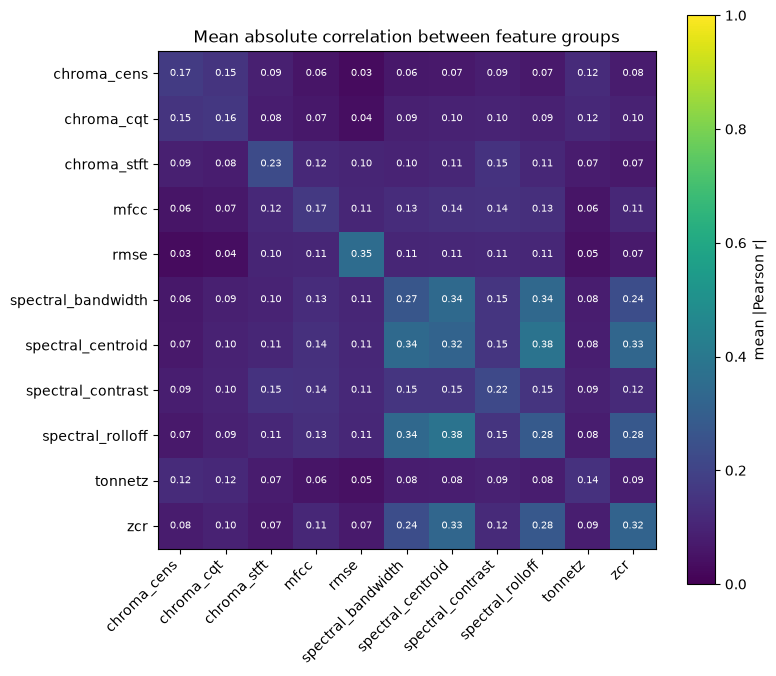

In [8]:
r = np.corrcoef(X.to_numpy(), rowvar=False)
n = len(feat_cols)
high = int((np.abs(np.triu(r, k=1)) > 0.9).sum())
print(f"feature pairs with |r| > 0.9: {high} of {n * (n - 1) // 2}")

# Mean |r| between descriptor groups, ignoring each feature's correlation with itself.
absr = np.abs(r)
np.fill_diagonal(absr, np.nan)
absr = pd.DataFrame(absr, index=feat_cols, columns=feat_cols)
group_r = absr.groupby(group).mean().T.groupby(group).mean()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(group_r, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(group_r)), group_r.columns, rotation=45, ha="right")
ax.set_yticks(range(len(group_r)), group_r.index)
for i in range(len(group_r)):
    for j in range(len(group_r)):
        v = group_r.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v < 0.6 else "k")
fig.colorbar(im, label="mean |Pearson r|")
ax.set_title("Mean absolute correlation between feature groups")
fig.tight_layout()
fig.savefig(FIGURES / "fma_group_correlation.png", dpi=200)

Correlated groups break Naive Bayes's assumption that features are independent given the genre, so Gaussian NB will count the same evidence several times.

## 6. Relevance to each genre

In [9]:
# One-vs-rest Pearson r between each feature and the indicator 1[genre == g]:
# r = mean(z_feature * z_indicator), with both standardised using the population std.
Y = pd.get_dummies(y).astype(float)
zx = (X - X.mean()) / X.std(ddof=0)
zy = (Y - Y.mean()) / Y.std(ddof=0)
R = zx.T @ zy / len(X)  # 518 features x 8 genres

top5 = pd.DataFrame({g: [f"{f} ({R.loc[f, g]:+.2f})" for f in R[g].abs().nlargest(5).index]
                     for g in genres}, index=range(1, 6)).T
top5

,1,2,3,4,5
Electronic,mfcc_median_20 (+0.29),mfcc_mean_20 (+0.28),mfcc_median_16 (+0.25),spectral_rolloff_std_01 (+0.25),rmse_std_01 (+0.25)
Experimental,spectral_contrast_max_07 (-0.18),mfcc_max_04 (-0.18),mfcc_mean_04 (-0.17),mfcc_median_04 (-0.17),chroma_cens_std_10 (-0.16)
Folk,spectral_contrast_median_02 (+0.31),spectral_contrast_mean_02 (+0.31),mfcc_mean_16 (-0.30),mfcc_median_16 (-0.30),mfcc_median_12 (-0.29)
Hip-Hop,rmse_std_01 (+0.31),mfcc_std_06 (+0.26),mfcc_max_06 (+0.26),mfcc_max_04 (+0.25),mfcc_std_04 (+0.25)
Instrumental,mfcc_mean_01 (-0.36),mfcc_median_01 (-0.36),spectral_bandwidth_median_01 (-0.34),spectral_contrast_mean_07 (-0.34),spectral_bandwidth_mean_01 (-0.33)
International,mfcc_std_02 (-0.18),mfcc_std_20 (+0.18),mfcc_min_20 (-0.17),mfcc_min_05 (-0.17),mfcc_min_10 (-0.17)
Pop,mfcc_median_01 (+0.11),mfcc_skew_03 (+0.10),mfcc_min_05 (-0.10),mfcc_mean_01 (+0.10),mfcc_skew_01 (-0.09)
Rock,mfcc_skew_01 (-0.31),mfcc_median_03 (-0.30),mfcc_mean_03 (-0.29),spectral_contrast_std_04 (-0.27),mfcc_median_01 (+0.27)


chroma_cens           0.107
chroma_cqt            0.115
tonnetz               0.127
chroma_stft           0.129
zcr                   0.169
mfcc                  0.189
spectral_contrast     0.199
rmse                  0.200
spectral_bandwidth    0.211
spectral_rolloff      0.220
spectral_centroid     0.222
dtype: float64

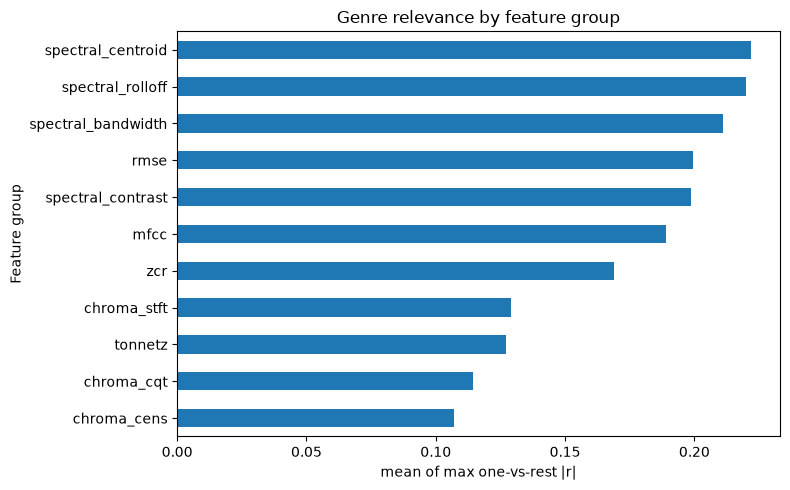

In [10]:
# A feature's relevance = its strongest |r| with any genre; averaged per descriptor group.
relevance = R.abs().max(axis=1).groupby(group).mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
relevance.plot.barh(ax=ax)
ax.set(xlabel="mean of max one-vs-rest |r|", ylabel="Feature group", title="Genre relevance by feature group")
fig.tight_layout()
fig.savefig(FIGURES / "fma_group_relevance.png", dpi=200)
relevance.round(3)

## 7. PCA

components for 90% variance: 143, for 95%: 204


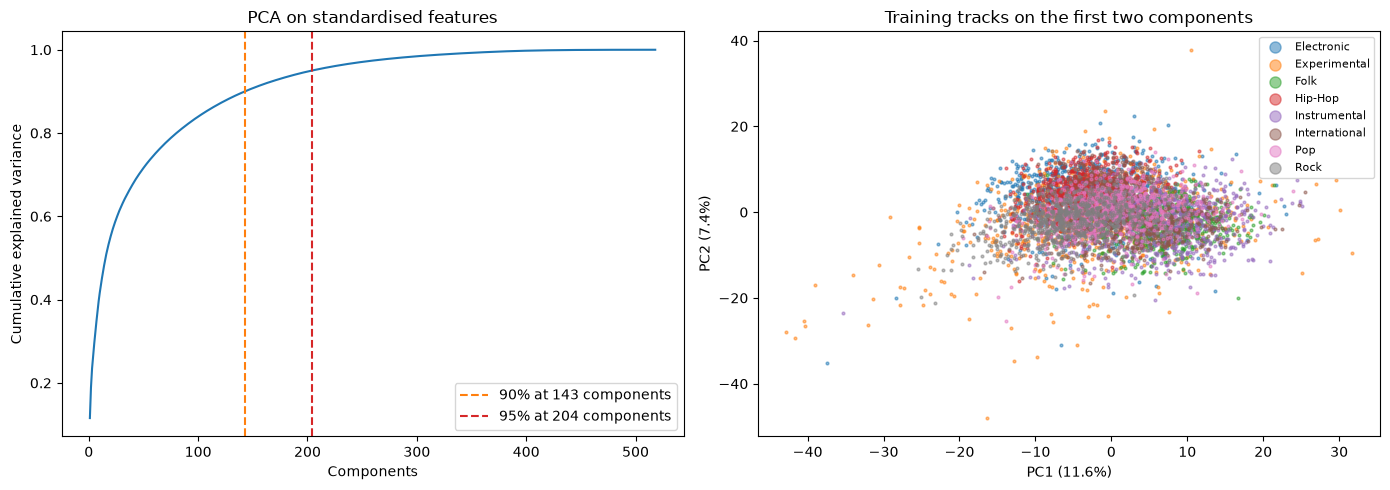

In [11]:
Xs = StandardScaler().fit_transform(X)
pca = PCA(random_state=SEED).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
k90, k95 = int(np.searchsorted(cum, 0.90)) + 1, int(np.searchsorted(cum, 0.95)) + 1
pcs = pca.transform(Xs)[:, :2]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(range(1, len(cum) + 1), cum)
for k, c in ((k90, "tab:orange"), (k95, "tab:red")):
    a1.axvline(k, color=c, ls="--", label=f"{cum[k - 1]:.0%} at {k} components")
a1.set(xlabel="Components", ylabel="Cumulative explained variance", title="PCA on standardised features")
a1.legend()
for g in genres:
    m = (y == g).to_numpy()
    a2.scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.5, label=g)
a2.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
       title="Training tracks on the first two components")
a2.legend(markerscale=4, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "fma_pca.png", dpi=200)
print(f"components for 90% variance: {k90}, for 95%: {k95}")

## Findings

Fill in from the outputs above (these go straight into the report):

- Class balance:
- Data quality (duplicates, outliers):
- Scale and skew:
- Redundancy (|r| > 0.9 pairs, most correlated groups):
- Most relevant feature groups and top features per genre:
- PCA (components for 90% / 95%, how well genres separate in 2-D):